### Test model performance on different train-test splits by iteratively adjusting data distributions, evaluating shifts in accuracy, and ensuring stability across multiple randomized and stratified splits.

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [14]:
df = pd.read_csv("heart_disease.csv")

print("Dataset loaded successfully")
print("Dataset shape:", df.shape)

display(df.head())
print(df.columns.tolist())

Dataset loaded successfully
Dataset shape: (25, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


In [15]:
print(df.columns.tolist())

target_column = "target"

if target_column not in df.columns:
    raise ValueError(
        f"'{target_column}' not found. "
        f"Available columns: {df.columns.tolist()}"
    )

df = df.dropna(subset=[target_column]).copy()

X = df.drop(columns=[target_column])
y = df[target_column]

X = pd.get_dummies(X, drop_first=True, dtype=int)

if not pd.api.types.is_numeric_dtype(y):
    y = pd.factorize(y)[0]

X = X.reset_index(drop=True)
y = pd.Series(np.asarray(y).ravel()).reset_index(drop=True)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())

['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']
X shape: (25, 13)
y shape: (25,)

Target distribution:
1    16
0     9
Name: count, dtype: int64


In [16]:
models = {
    "Logistic Regression": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(max_iter=2000, random_state=42)
    ),

    "KNN": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    "SVM": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        SVC(probability=True, random_state=42)
    ),

    "Decision Tree": make_pipeline(
        SimpleImputer(strategy="median"),
        DecisionTreeClassifier(random_state=42)
    ),

    "Random Forest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestClassifier(
            n_estimators=100,
            random_state=42
        )
    )
}

print("Models defined successfully")

Models defined successfully


In [17]:
results = []

test_sizes = [0.30, 0.25, 0.20]
random_seeds = [11, 21, 42, 55, 75]

for test_size in test_sizes:
    for seed in random_seeds:

        for method in ["Random", "Stratified"]:

            stratify = y if method == "Stratified" else None

            if method == "Stratified" and y.value_counts().min() < 2:
                continue

            try:
                X_train, X_test, y_train, y_test = train_test_split(
                    X,
                    y,
                    test_size=test_size,
                    random_state=seed,
                    stratify=stratify
                )
            except ValueError as e:
                print("Split skipped:", e)
                continue

            for name, model in models.items():

                fitted_model = clone(model)
                fitted_model.fit(X_train, y_train)

                y_pred = fitted_model.predict(X_test)

                auc = np.nan

                if y.nunique() == 2:
                    try:
                        y_score = fitted_model.predict_proba(X_test)[:, 1]
                        auc = roc_auc_score(y_test, y_score)
                    except (ValueError, IndexError):
                        pass

                results.append({
                    "Model": name,
                    "Train Size": round(1 - test_size, 2),
                    "Test Size": test_size,
                    "Split Method": method,
                    "Random Seed": seed,
                    "Accuracy": accuracy_score(y_test, y_pred),
                    "Precision": precision_score(
                        y_test, y_pred,
                        average="weighted",
                        zero_division=0
                    ),
                    "Recall": recall_score(
                        y_test, y_pred,
                        average="weighted",
                        zero_division=0
                    ),
                    "F1 Score": f1_score(
                        y_test, y_pred,
                        average="weighted",
                        zero_division=0
                    ),
                    "ROC-AUC": auc
                })

results_df = pd.DataFrame(results)

display(results_df.head(10))
print("Total experiments:", len(results_df))

C:\Users\Bhagyashri\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\Bhagyashri\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\Bhagyashri\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\Bhagyashri\AppData\Local\Programs\Python\Python313\Lib\site-p

,Model,Train Size,Test Size,Split Method,Random Seed,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7,0.3,Random,11,0.750,0.750000,0.750,0.750000,0.714286
1,KNN,0.7,0.3,Random,11,0.625,0.729167,0.625,0.673077,0.571429
2,SVM,0.7,0.3,Random,11,0.750,0.916667,0.750,0.791667,1.000000
3,Decision Tree,0.7,0.3,Random,11,0.750,0.750000,0.750,0.750000,0.428571
4,Random Forest,0.7,0.3,Random,11,0.875,0.937500,0.875,0.891026,1.000000
5,Logistic Regression,0.7,0.3,Stratified,11,0.750,0.850000,0.750,0.750000,0.800000
6,KNN,0.7,0.3,Stratified,11,0.625,0.604167,0.625,0.604545,0.766667
7,SVM,0.7,0.3,Stratified,11,0.625,0.604167,0.625,0.604545,0.666667
8,Decision Tree,0.7,0.3,Stratified,11,0.500,0.566667,0.500,0.500000,0.533333
9,Random Forest,0.7,0.3,Stratified,11,0.625,0.656250,0.625,0.630952,0.733333


Total experiments: 150


In [18]:
summary = results_df.groupby("Model").agg(
    Mean_Accuracy=("Accuracy", "mean"),
    Std_Accuracy=("Accuracy", "std"),
    Mean_Precision=("Precision", "mean"),
    Mean_Recall=("Recall", "mean"),
    Mean_F1=("F1 Score", "mean"),
    Mean_ROC_AUC=("ROC-AUC", "mean")
).round(4)

display(summary.sort_values("Mean_Accuracy", ascending=False))

,Mean_Accuracy,Std_Accuracy,Mean_Precision,Mean_Recall,Mean_F1,Mean_ROC_AUC
Model,,,,,,
SVM,0.7506,0.1418,0.7827,0.7506,0.7376,0.8713
Logistic Regression,0.7443,0.1416,0.7730,0.7443,0.7391,0.8229
KNN,0.7295,0.1480,0.7279,0.7295,0.7001,0.8263
Random Forest,0.7125,0.1386,0.7401,0.7125,0.7008,0.8431
Decision Tree,0.6386,0.2082,0.6501,0.6386,0.6332,0.5573


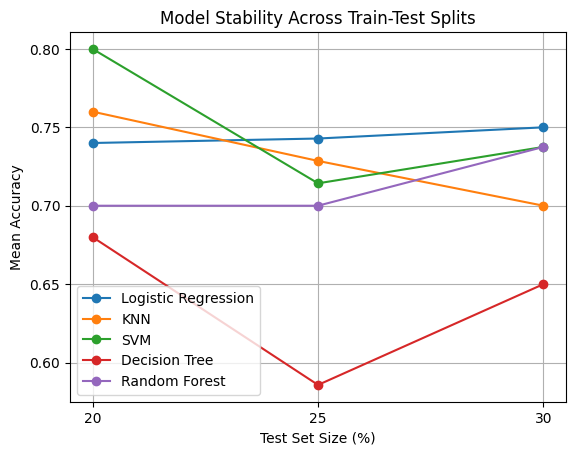

In [19]:
plot_data = results_df.groupby(
    ["Model", "Test Size"]
)["Accuracy"].mean().reset_index()

for name in models:
    data = plot_data[plot_data["Model"] == name]

    plt.plot(
        data["Test Size"] * 100,
        data["Accuracy"],
        marker="o",
        label=name
    )

plt.xlabel("Test Set Size (%)")
plt.ylabel("Mean Accuracy")
plt.title("Model Stability Across Train-Test Splits")
plt.xticks([20, 25, 30])
plt.legend()
plt.grid(True)
plt.show()

In [20]:
stability = results_df.groupby("Model")["Accuracy"].agg(
    ["mean", "std", "min", "max"]
).round(4)

stability["Accuracy_Range"] = (
    stability["max"] - stability["min"]
)

display(stability.sort_values("std", ascending=True))

,mean,std,min,max,Accuracy_Range
Model,,,,,
Random Forest,0.7125,0.1386,0.4000,1.0,0.6000
Logistic Regression,0.7443,0.1416,0.4000,1.0,0.6000
SVM,0.7506,0.1418,0.5714,1.0,0.4286
KNN,0.7295,0.1480,0.4000,1.0,0.6000
Decision Tree,0.6386,0.2082,0.2000,1.0,0.8000
